#  Transfer Learning — Approach 2: Fine-Tuning
### MobileNetV2 on the Flowers Dataset

This notebook builds the **same MobileNetV2 architecture** as the feature-extraction notebook, re-loads the data from scratch, trains the head (warm-up), then **unfreezes the top layers of the base model** and continues training at a much lower learning rate.

> **Comparability note:** All shared hyperparameters (image size, batch size, seed, dropout rate, learning rates, epoch ceilings, early-stopping settings) are defined in one config cell below — **identical** to the feature-extraction notebook — so metrics from the two notebooks can be compared apples-to-apples later.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import pathlib, os, tarfile, urllib.request, urllib.error, time, shutil, json


SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
IMG_SHAPE = IMG_SIZE + (3,)

DROPOUT_RATE = 0.3
BASE_LR = 1e-3            # LR for training the classification head
FT_LR = 1e-5              # LR for fine-tuning unfrozen base layers (100x smaller)
FINE_TUNE_AT = 100        # freeze base_model layers[:FINE_TUNE_AT], unfreeze the rest

MAX_EPOCHS_HEAD = 30      # ceiling epochs for head / warm-up training
MAX_EPOCHS_FT = 20        # ceiling epochs for the fine-tuning phase
EARLY_STOPPING_PATIENCE = 5
EARLY_STOPPING_MONITOR = 'val_loss'

RESULTS_DIR = 'tl_results'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
def robust_download(url, dest_dir, filename, max_retries=3, min_bytes=100_000, timeout=30):
    """Download a file with retries, timeout, and a minimum-size sanity check.
    Returns the local path on success. Raises RuntimeError with a clear message on failure."""
    os.makedirs(dest_dir, exist_ok=True)
    dest_path = os.path.join(dest_dir, filename)

    if os.path.exists(dest_path) and os.path.getsize(dest_path) >= min_bytes:
        print(f"✔ Using cached file: {dest_path} ({os.path.getsize(dest_path)/1e6:.1f} MB)")
        return dest_path

    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            print(f"Downloading (attempt {attempt}/{max_retries}) from {url} ...")
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=timeout) as response, open(dest_path, 'wb') as out_file:
                shutil.copyfileobj(response, out_file)

            size = os.path.getsize(dest_path)
            if size < min_bytes:
                raise IOError(f"Downloaded file is suspiciously small ({size} bytes) — likely an error page, not the real dataset.")

            print(f"✔ Downloaded {size/1e6:.1f} MB -> {dest_path}")
            return dest_path

        except Exception as e:
            last_err = e
            print(f"  ✘ Attempt {attempt} failed: {type(e).__name__}: {e}")
            if os.path.exists(dest_path):
                os.remove(dest_path)
            if attempt < max_retries:
                wait = 2 * attempt
                print(f"  Retrying in {wait}s ...")
                time.sleep(wait)

    raise RuntimeError(
        f"Failed to download '{url}' after {max_retries} attempts.\n"
        f"Last error: {last_err}\n"
        f"This usually means no internet access, a firewall/proxy block, or a dead link.\n"
        f"Falling back to tensorflow_datasets in the next cell."
    )


def robust_extract_tgz(tgz_path, extract_dir):
    """Extract a .tgz archive with a clear error if it fails or is empty."""
    os.makedirs(extract_dir, exist_ok=True)
    try:
        with tarfile.open(tgz_path, 'r:gz') as tar:
            tar.extractall(path=extract_dir)
    except Exception as e:
        raise RuntimeError(f"Failed to extract '{tgz_path}': {type(e).__name__}: {e}")

    extracted_items = list(pathlib.Path(extract_dir).rglob('*.jpg'))
    if len(extracted_items) == 0:
        raise RuntimeError(f"Extraction of '{tgz_path}' produced zero .jpg files — archive may be corrupted or incomplete.")

    print(f"✔ Extracted {len(extracted_items)} .jpg files into {extract_dir}")
    return extract_dir


In [ ]:
# ---- Primary path: direct download of the official TensorFlow flowers archive ----
FLOWERS_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
CACHE_DIR = os.path.join(os.path.expanduser('~'), '.keras_datasets_manual')

data_dir = None
loading_method = None

try:
    tgz_path = robust_download(FLOWERS_URL, CACHE_DIR, 'flower_photos.tgz', max_retries=3, min_bytes=100_000)
    extract_root = os.path.join(CACHE_DIR, 'flower_photos_extracted')
    robust_extract_tgz(tgz_path, extract_root)

    # The archive extracts to <extract_root>/flower_photos/<class>/*.jpg
    candidate = pathlib.Path(extract_root) / 'flower_photos'
    if not candidate.exists():
        # some tar builds extract without the wrapper folder — search for it
        found = list(pathlib.Path(extract_root).rglob('flower_photos'))
        candidate = found[0] if found else pathlib.Path(extract_root)

    data_dir = candidate
    loading_method = 'direct_download'

except Exception as e:
    print(f"\n⚠ Primary download path failed: {e}\n")
    data_dir = None


✔ Downloaded 228.8 MB -> /root/.keras_datasets_manual/flower_photos.tgz


/tmp/ipykernel_6411/3623732832.py:49: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


✔ Extracted 3670 .jpg files into /root/.keras_datasets_manual/flower_photos_extracted


In [ ]:
# ---- Fallback path: tensorflow_datasets (different infrastructure/CDN) ----
if data_dir is None:
    print("Attempting fallback via tensorflow_datasets ('tf_flowers') ...")
    try:
        import tensorflow_datasets as tfds
    except ImportError:
        raise RuntimeError(
            "tensorflow_datasets is not installed and the primary download also failed.\n"
            "Fix with: pip install tensorflow-datasets --break-system-packages\n"
            "Then re-run this cell."
        )

    try:
        tfds_dataset, tfds_info = tfds.load('tf_flowers', split='train', with_info=True, as_supervised=True)
        tfds_class_names = tfds_info.features['label'].names
        loading_method = 'tfds'
        print(f"✔ Loaded tf_flowers via tensorflow_datasets: {tfds_info.splits['train'].num_examples} images, classes={tfds_class_names}")
    except Exception as e:
        raise RuntimeError(
            f"Both the direct download AND tensorflow_datasets fallback failed.\n"
            f"tensorflow_datasets error: {type(e).__name__}: {e}\n"
            f"This strongly suggests there is NO internet access in this environment.\n"
            f"Please check your network/proxy settings, or manually download flower_photos.tgz\n"
            f"from {FLOWERS_URL} and place the extracted folder at a path of your choice,\n"
            f"then set `data_dir = pathlib.Path('<your_path>')` manually before re-running."
        )
else:
    print(f"✔ Using directly-downloaded dataset at: {data_dir}")


✔ Using directly-downloaded dataset at: /root/.keras_datasets_manual/flower_photos_extracted/flower_photos


In [ ]:
# ---- Hard verification: refuse to proceed on empty/missing data ----
# NOTE: IMG_SIZE / BATCH_SIZE / SEED already come from the shared config cell above.

if loading_method == 'direct_download':
    assert data_dir is not None and pathlib.Path(data_dir).exists(), \
        f"data_dir '{data_dir}' does not exist after extraction — aborting."

    class_dirs = [d for d in pathlib.Path(data_dir).iterdir() if d.is_dir()]
    assert len(class_dirs) > 0, f"No class subfolders found inside '{data_dir}' — aborting."

    image_count = len(list(pathlib.Path(data_dir).glob('*/*.jpg')))
    assert image_count > 0, f"Zero images found inside '{data_dir}' — aborting (empty dataset, will not train)."

    class_names_raw = sorted([d.name for d in class_dirs])
    print(f"✔ VERIFIED: {image_count} images across {len(class_names_raw)} classes: {class_names_raw}")

    for c in class_names_raw:
        n = len(list((pathlib.Path(data_dir) / c).glob('*.jpg')))
        assert n > 0, f"Class '{c}' has 0 images — aborting."
        print(f"    {c:12s}: {n} images")

    train_ds = keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="training",
        seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
    )
    val_ds = keras.utils.image_dataset_from_directory(
        data_dir, validation_split=0.2, subset="validation",
        seed=SEED, image_size=IMG_SIZE, batch_size=BATCH_SIZE
    )
    class_names = train_ds.class_names

elif loading_method == 'tfds':
    class_names = tfds_class_names

    def _prep(image, label):
        image = tf.image.resize(image, IMG_SIZE)
        return image, label

    full_ds = tfds_dataset.map(_prep, num_parallel_calls=tf.data.AUTOTUNE)
    total = tfds_info.splits['train'].num_examples
    assert total > 0, "tensorflow_datasets reported zero examples — aborting."

    full_ds = full_ds.shuffle(1000, seed=SEED)
    val_size = int(0.2 * total)
    val_full = full_ds.take(val_size).batch(BATCH_SIZE)
    train_ds = full_ds.skip(val_size).batch(BATCH_SIZE)
    val_ds = val_full
    print(f"✔ VERIFIED: {total} images across {len(class_names)} classes (via tensorflow_datasets): {class_names}")

else:
    raise RuntimeError("No valid loading_method was set — this should never happen. Aborting.")

num_classes = len(class_names)

# Final hard check BEFORE we let any training cell run
train_cardinality = tf.data.experimental.cardinality(train_ds).numpy()
val_cardinality = tf.data.experimental.cardinality(val_ds).numpy()
assert train_cardinality > 0, "train_ds has ZERO batches — refusing to proceed to model training."
assert val_cardinality > 0, "val_ds has ZERO batches — refusing to proceed to model training."
print(f"\n✔ train_ds batches: {train_cardinality} | val_ds batches: {val_cardinality} | classes: {class_names}")


✔ VERIFIED: 3670 images across 5 classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
    daisy       : 633 images
    dandelion   : 898 images
    roses       : 641 images
    sunflowers  : 699 images
    tulips      : 799 images
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.

✔ train_ds batches: 92 | val_ds batches: 23 | classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [ ]:
# Split validation into val + test (50/50), with the same zero-batch guard
val_batches = tf.data.experimental.cardinality(val_ds)
assert val_batches.numpy() >= 2, "Not enough validation batches to split into val/test — need at least 2."

test_ds = val_ds.take(val_batches // 2)
val_ds = val_ds.skip(val_batches // 2)

assert tf.data.experimental.cardinality(test_ds).numpy() > 0, "test_ds ended up empty after split — aborting."
assert tf.data.experimental.cardinality(val_ds).numpy() > 0, "val_ds ended up empty after split — aborting."

print('Training batches:   %d' % tf.data.experimental.cardinality(train_ds))
print('Validation batches: %d' % tf.data.experimental.cardinality(val_ds))
print('Test batches:       %d' % tf.data.experimental.cardinality(test_ds))


Training batches:   92
Validation batches: 12
Test batches:       11


## 2️⃣ Data Exploration & Visualization

Quick sanity checks before training — sample images and the class distribution.


✔ First batch shape: images=(32, 160, 160, 3), labels=(32,)
✔ Pixel value range: [0.0, 255.0]


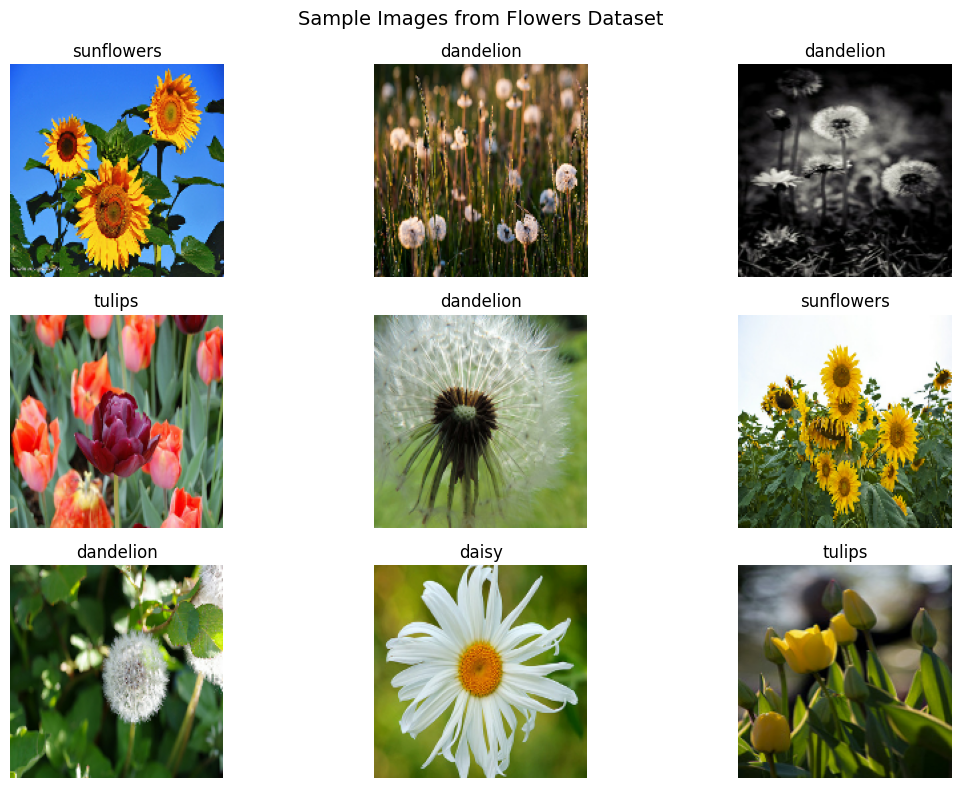

In [ ]:
# Sanity-check the very first batch before doing anything else
sample_images, sample_labels = next(iter(train_ds))
assert sample_images.shape[0] > 0, "First training batch is empty — aborting before wasting compute on training."
print(f"✔ First batch shape: images={sample_images.shape}, labels={sample_labels.shape}")
print(f"✔ Pixel value range: [{tf.reduce_min(sample_images).numpy():.1f}, {tf.reduce_max(sample_images).numpy():.1f}]")

plt.figure(figsize=(12, 8))
for i in range(min(9, sample_images.shape[0])):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(sample_images[i].numpy().astype("uint8"))
    plt.title(class_names[sample_labels[i]])
    plt.axis("off")
plt.suptitle("Sample Images from Flowers Dataset", fontsize=14)
plt.tight_layout()
plt.show()


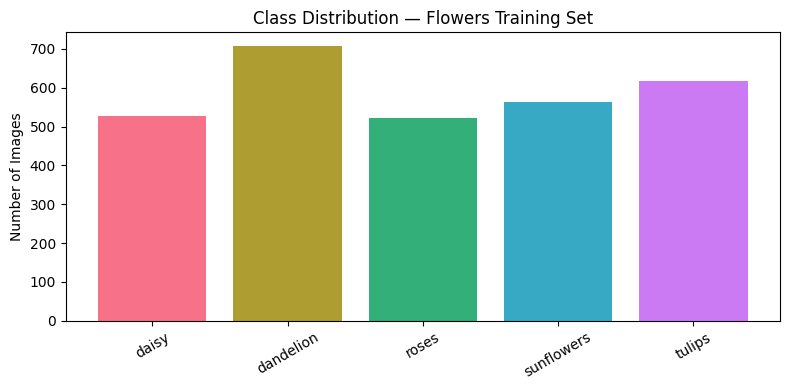

daisy       : 526 images
dandelion   : 707 images
roses       : 522 images
sunflowers  : 564 images
tulips      : 617 images


In [ ]:
# Class distribution (works for both loading paths since we iterate the actual dataset)
from collections import Counter

label_counter = Counter()
for _, labels in train_ds.unbatch():
    label_counter[int(labels.numpy())] += 1

assert sum(label_counter.values()) > 0, "No labels counted — training set is empty."

counts_named = {class_names[k]: v for k, v in sorted(label_counter.items())}
plt.figure(figsize=(8, 4))
plt.bar(counts_named.keys(), counts_named.values(), color=sns.color_palette("husl", len(counts_named)))
plt.title("Class Distribution — Flowers Training Set")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

for c, n in counts_named.items():
    print(f"{c:12s}: {n} images")


In [ ]:
# Performance optimization: prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)


## 3️⃣ Data Augmentation Pipeline

Since the dataset is relatively small (~3670 images across 5 classes), augmentation artificially expands diversity to reduce overfitting.


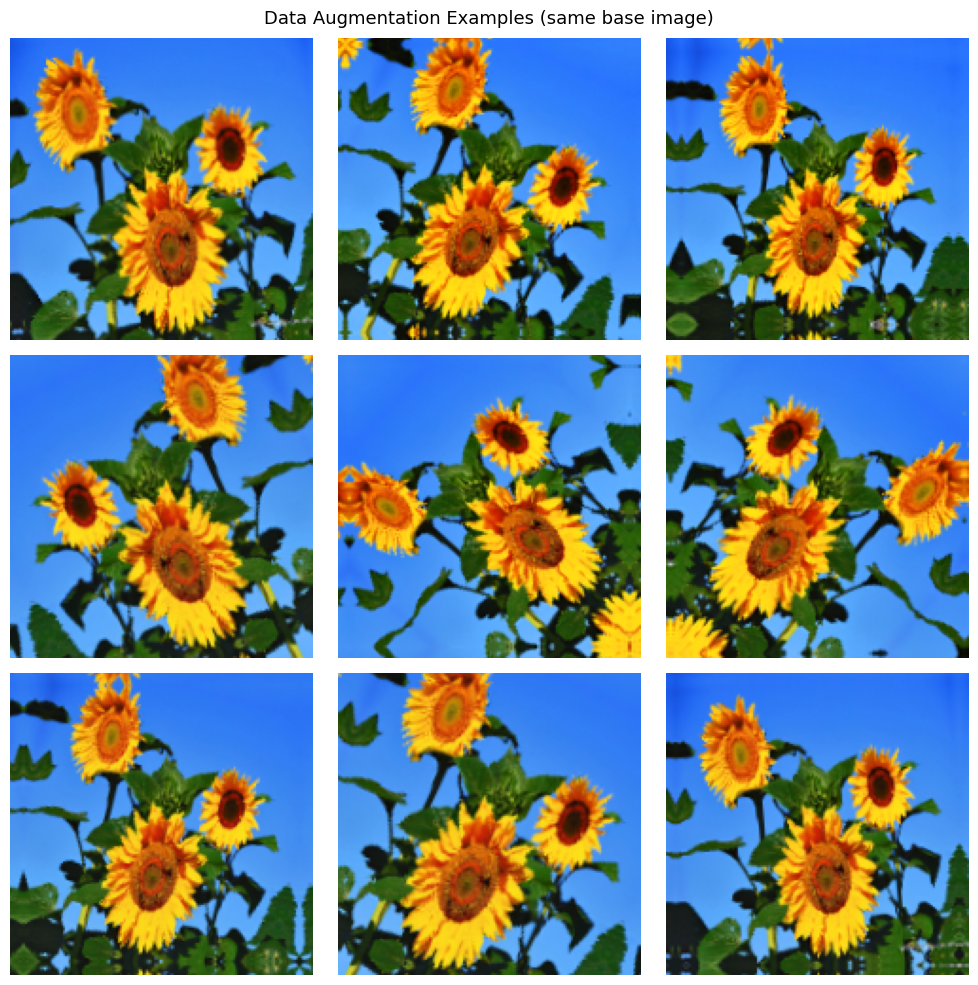

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),
], name="data_augmentation")

# Visualize augmentation effect
plt.figure(figsize=(10, 10))
first_image = sample_images[0]
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0), training=True)
    plt.imshow(augmented_image[0].numpy().astype("uint8"))
    plt.axis('off')
plt.suptitle("Data Augmentation Examples (same base image)", fontsize=13)
plt.tight_layout()
plt.show()


## 4️⃣ Model — Same MobileNetV2 Architecture

Same base architecture and head as the feature-extraction notebook:
1. Load `MobileNetV2` pretrained on ImageNet, without its classification top.
2. Freeze the entire base **for now** (Phase 1 warm-up).
3. Add the same classification head (`GlobalAveragePooling2D` + `Dropout` + `Dense`).

Fine-tuning needs a reasonably trained head *before* unfreezing base layers — unfreezing convolutional layers underneath a randomly-initialized head would send large, noisy gradients into the pretrained weights and destroy them. So Phase 1 below reproduces the feature-extraction warm-up with **identical hyperparameters**, then Phase 2 unfreezes and fine-tunes.


In [ ]:
def load_mobilenet_base(weights_pref='imagenet', max_retries=3):
    last_err = None
    for attempt in range(1, max_retries + 1):
        try:
            base = MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights=weights_pref)
            print(f"✔ Loaded MobileNetV2 with weights='{weights_pref}'")
            return base
        except Exception as e:
            last_err = e
            print(f"  ✘ Attempt {attempt}/{max_retries} to load weights='{weights_pref}' failed: {e}")
            time.sleep(2 * attempt)

    print(f"\n⚠ Could not download ImageNet weights after {max_retries} attempts ({last_err}).")
    print("⚠ Falling back to weights=None (random init) — this defeats the purpose of transfer learning,")
    print("⚠ but keeps the notebook runnable end-to-end even fully offline.")
    return MobileNetV2(input_shape=IMG_SHAPE, include_top=False, weights=None)

base_model = load_mobilenet_base(weights_pref='imagenet')
base_model.trainable = False   # start frozen — Phase 1 warm-up


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✔ Loaded MobileNetV2 with weights='imagenet'


In [ ]:
# Build the full model (identical architecture to the feature-extraction notebook)
inputs = keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(DROPOUT_RATE)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)
fine_tune_model = keras.Model(inputs, outputs, name="fine_tuned_mobilenetv2")

fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=BASE_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
fine_tune_model.summary()


Model: "fine_tuned_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5️⃣ Phase 1 — Warm-Up Training (Frozen Base)

Trains only the head, up to `MAX_EPOCHS_HEAD` epochs with the same early-stopping settings as the feature-extraction notebook. This gives the head a sensible starting point before we unfreeze anything.


In [ ]:
assert tf.data.experimental.cardinality(train_ds).numpy() > 0, "Refusing to call .fit() on an empty train_ds."

trainable_count_phase1 = np.sum([tf.keras.backend.count_params(w) for w in fine_tune_model.trainable_weights])
assert trainable_count_phase1 > 0, "Zero trainable parameters in Phase 1 — aborting."
print(f"Phase 1 trainable params: {trainable_count_phase1:,}")

early_stop_phase1 = EarlyStopping(
    monitor=EARLY_STOPPING_MONITOR,
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

history_warmup = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS_HEAD,
    callbacks=[early_stop_phase1]
)

EPOCHS_TRAINED_WARMUP = len(history_warmup.history['loss'])
print(f"\n✔ Phase 1 stopped after {EPOCHS_TRAINED_WARMUP} epoch(s) (ceiling was {MAX_EPOCHS_HEAD}).")


Phase 1 trainable params: 6,405
Epoch 1/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 15s 85ms/step - accuracy: 0.6383 - loss: 0.9576 - val_accuracy: 0.7984 - val_loss: 0.5231
Epoch 2/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8130 - loss: 0.5283 - val_accuracy: 0.8194 - val_loss: 0.4805
Epoch 3/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.8300 - loss: 0.4424 - val_accuracy: 0.8272 - val_loss: 0.4255
Epoch 4/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.8495 - loss: 0.4094 - val_accuracy: 0.8403 - val_loss: 0.4272
Epoch 5/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - accuracy: 0.8600 - loss: 0.3815 - val_accuracy: 0.8429 - val_loss: 0.4168
Epoch 6/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.8808 - loss: 0.3406 - val_accuracy: 0.8560 - val_loss: 0.3908
Epoch 7/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.8757 - loss: 0.3296 - val_accuracy: 0.8508 - val_loss: 0.4322
Epoch 8/30
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 67ms/step - accuracy: 0.8760 - loss: 

## 6️⃣ Phase 2 — Unfreeze & Fine-Tune

Unfreeze the top layers of the base model (everything from index `FINE_TUNE_AT` onward), recompile with the much smaller `FT_LR`, and continue training with early stopping again.


In [ ]:
base_model.trainable = True   # unlock the base model

total_base_layers = len(base_model.layers)
assert total_base_layers > 0, "Base model has zero layers — cannot fine-tune."

fine_tune_at = min(FINE_TUNE_AT, total_base_layers - 1)   # never unfreeze beyond what exists

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

trainable_layers = sum(1 for l in base_model.layers if l.trainable)
assert trainable_layers > 0, "Zero layers unfrozen for fine-tuning — check FINE_TUNE_AT."
print(f"Total layers in base model: {total_base_layers}")
print(f"Layers unfrozen for fine-tuning: {trainable_layers}")


Total layers in base model: 154
Layers unfrozen for fine-tuning: 54


In [ ]:
# Recompile with a MUCH lower learning rate — critical for fine-tuning
fine_tune_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FT_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

trainable_count_phase2 = np.sum([tf.keras.backend.count_params(w) for w in fine_tune_model.trainable_weights])
assert trainable_count_phase2 > 0, "Zero trainable parameters after unfreezing — aborting."
print(f"Phase 2 trainable params after unfreezing: {trainable_count_phase2:,}")


Phase 2 trainable params after unfreezing: 1,867,845


In [ ]:
early_stop_phase2 = EarlyStopping(
    monitor=EARLY_STOPPING_MONITOR,
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

total_epoch_ceiling = EPOCHS_TRAINED_WARMUP + MAX_EPOCHS_FT

history_finetune = fine_tune_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epoch_ceiling,
    initial_epoch=history_warmup.epoch[-1] + 1,   # continue epoch counting for smooth plots
    callbacks=[early_stop_phase2]
)

EPOCHS_TRAINED_FT = len(history_finetune.history['loss'])
print(f"\n✔ Phase 2 (fine-tuning) stopped after {EPOCHS_TRAINED_FT} additional epoch(s).")


Epoch 14/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 99ms/step - accuracy: 0.7728 - loss: 0.6302 - val_accuracy: 0.8560 - val_loss: 0.3839
Epoch 15/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 18s 92ms/step - accuracy: 0.8273 - loss: 0.4711 - val_accuracy: 0.8691 - val_loss: 0.3803
Epoch 16/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 7s 75ms/step - accuracy: 0.8471 - loss: 0.4147 - val_accuracy: 0.8770 - val_loss: 0.3737
Epoch 17/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.8597 - loss: 0.4004 - val_accuracy: 0.9031 - val_loss: 0.2787
Epoch 18/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 9s 95ms/step - accuracy: 0.8726 - loss: 0.3382 - val_accuracy: 0.8796 - val_loss: 0.3601
Epoch 19/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 8s 75ms/step - accuracy: 0.8655 - loss: 0.3502 - val_accuracy: 0.8586 - val_loss: 0.3641
Epoch 20/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.8798 - loss: 0.3222 - val_accuracy: 0.8953 - val_loss: 0.2896
Epoch 21/33
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 82ms/step - accuracy: 0.8917 - loss: 0.3027 - val_accuracy

## 7️⃣ Training Curves (Both Phases)


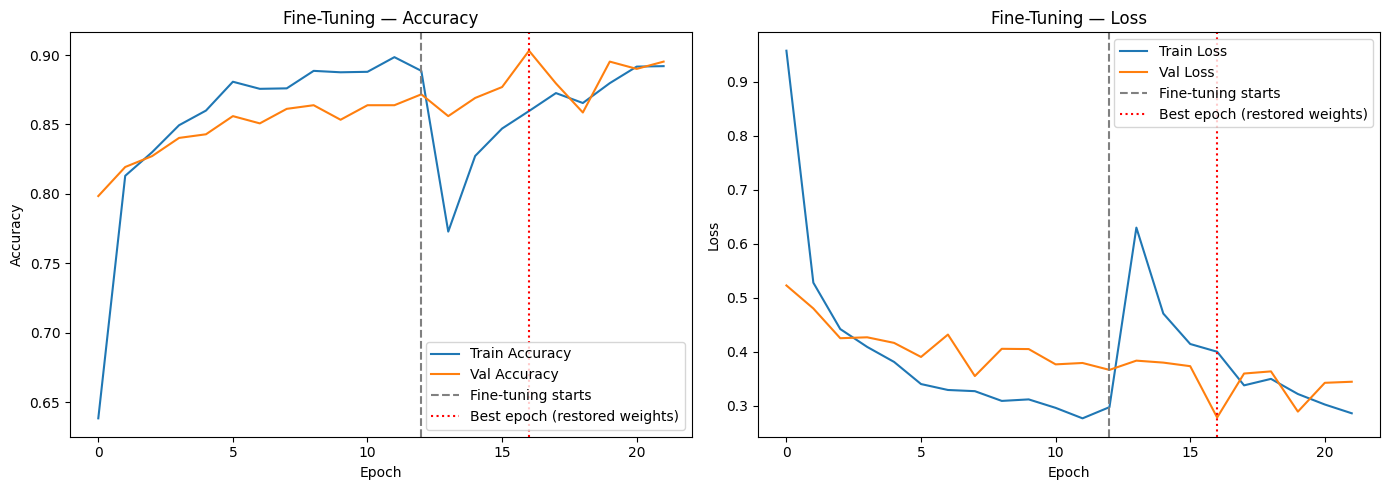

In [ ]:
acc = history_warmup.history['accuracy'] + history_finetune.history['accuracy']
val_acc = history_warmup.history['val_accuracy'] + history_finetune.history['val_accuracy']
loss = history_warmup.history['loss'] + history_finetune.history['loss']
val_loss = history_warmup.history['val_loss'] + history_finetune.history['val_loss']
phase_boundary = EPOCHS_TRAINED_WARMUP - 1
best_epoch = int(np.argmin(val_loss))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(acc, label='Train Accuracy')
axes[0].plot(val_acc, label='Val Accuracy')
axes[0].axvline(x=phase_boundary, color='gray', linestyle='--', label='Fine-tuning starts')
axes[0].axvline(x=best_epoch, color='red', linestyle=':', label='Best epoch (restored weights)')
axes[0].set_title('Fine-Tuning — Accuracy')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(loss, label='Train Loss')
axes[1].plot(val_loss, label='Val Loss')
axes[1].axvline(x=phase_boundary, color='gray', linestyle='--', label='Fine-tuning starts')
axes[1].axvline(x=best_epoch, color='red', linestyle=':', label='Best epoch (restored weights)')
axes[1].set_title('Fine-Tuning — Loss')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend()

plt.tight_layout()
plt.show()


## 8️⃣ Evaluation — Test Set, Confusion Matrix & Classification Report


In [ ]:
assert tf.data.experimental.cardinality(test_ds).numpy() > 0, "test_ds is empty — cannot evaluate."

test_loss_ft, test_acc_ft = fine_tune_model.evaluate(test_ds)
print(f"\nFinal Test Accuracy: {test_acc_ft*100:.2f}%")
print(f"Final Test Loss: {test_loss_ft:.4f}")


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8949 - loss: 0.3228

Final Test Accuracy: 89.49%
Final Test Loss: 0.3228


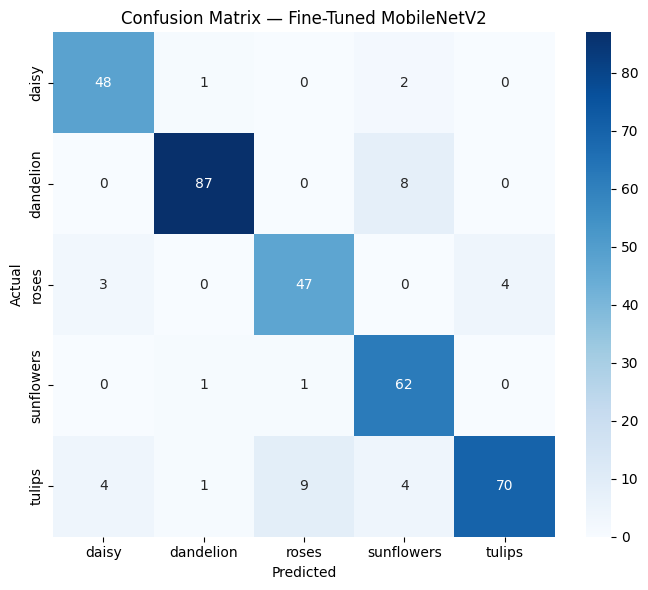

              precision    recall  f1-score   support

       daisy       0.87      0.94      0.91        51
   dandelion       0.97      0.92      0.94        95
       roses       0.82      0.87      0.85        54
  sunflowers       0.82      0.97      0.89        64
      tulips       0.95      0.80      0.86        88

    accuracy                           0.89       352
   macro avg       0.89      0.90      0.89       352
weighted avg       0.90      0.89      0.89       352



In [ ]:
# Confusion matrix + classification report
y_true_cm, y_pred_cm = [], []
for images, labels in test_ds:
    preds = fine_tune_model.predict(images, verbose=0)
    y_pred_cm.extend(np.argmax(preds, axis=1))
    y_true_cm.extend(labels.numpy())

assert len(y_true_cm) > 0, "No predictions collected — test_ds produced zero samples."

cm_ft = confusion_matrix(y_true_cm, y_pred_cm)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_ft, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix — Fine-Tuned MobileNetV2')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

report_ft = classification_report(y_true_cm, y_pred_cm, target_names=class_names, output_dict=True)
print(classification_report(y_true_cm, y_pred_cm, target_names=class_names))


## 9️⃣ Prediction Testing

A reusable prediction function, demoed on a few images, plus a grid of 6 correct and 6 incorrect predictions (same format as the feature-extraction notebook, for easy side-by-side comparison).


In [ ]:
def predict_flower(img_path_or_array, model=fine_tune_model):
    """Predict flower class for a single image (path or array)."""
    if isinstance(img_path_or_array, str):
        assert os.path.exists(img_path_or_array), f"Image path does not exist: {img_path_or_array}"
        img = keras.utils.load_img(img_path_or_array, target_size=IMG_SIZE)
        img_array = keras.utils.img_to_array(img)
    else:
        img_array = img_path_or_array
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array, verbose=0)
    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = np.max(predictions[0]) * 100

    print(f"Predicted: {predicted_class}  ({confidence:.2f}% confidence)")
    return predicted_class, confidence

# Demo on a handful of test-set images
demo_images, demo_labels = next(iter(test_ds))
for i in range(min(5, demo_images.shape[0])):
    print(f"Actual: {class_names[demo_labels[i].numpy()]}")
    predict_flower(demo_images[i].numpy())
    print()


Actual: tulips
Predicted: tulips  (94.67% confidence)

Actual: dandelion
Predicted: dandelion  (49.32% confidence)

Actual: daisy
Predicted: daisy  (99.37% confidence)

Actual: sunflowers
Predicted: sunflowers  (59.92% confidence)

Actual: dandelion
Predicted: dandelion  (100.00% confidence)



/tmp/ipykernel_6411/2945490498.py:40: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


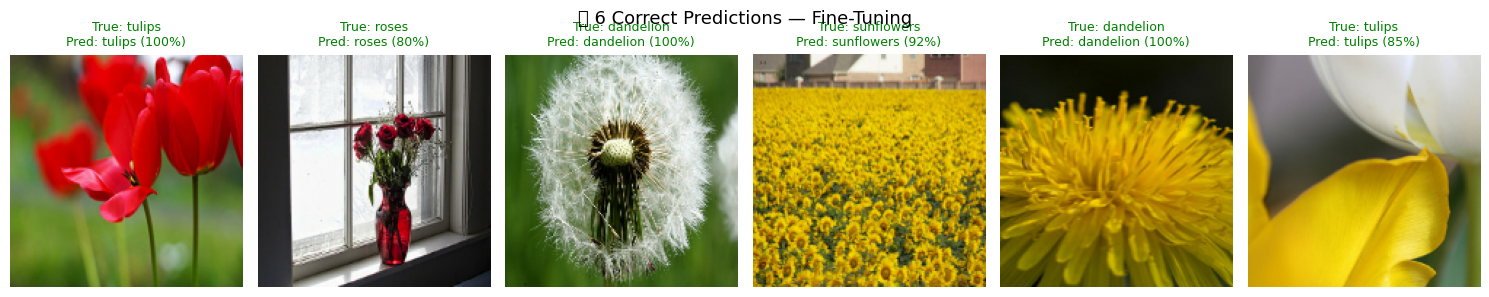

/tmp/ipykernel_6411/2945490498.py:40: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


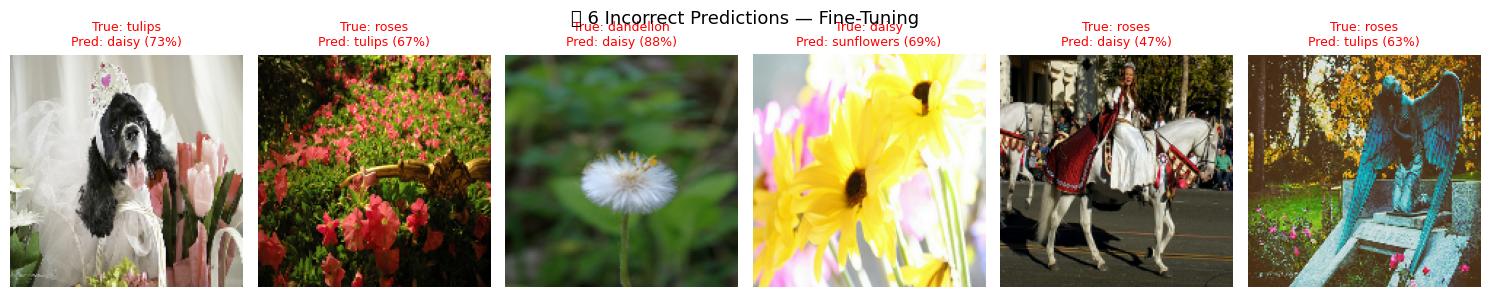

In [ ]:
# Collect per-image predictions on the full test set
y_true, y_pred, y_conf, all_images = [], [], [], []

for images, labels in test_ds:
    preds = fine_tune_model.predict(images, verbose=0)
    pred_classes = np.argmax(preds, axis=1)
    confidences = np.max(preds, axis=1)
    y_true.extend(labels.numpy())
    y_pred.extend(pred_classes)
    y_conf.extend(confidences)
    all_images.extend(images.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_conf = np.array(y_conf)
assert len(y_true) > 0, "No predictions collected — test_ds produced zero samples."

correct_idx = np.where(y_true == y_pred)[0]
wrong_idx = np.where(y_true != y_pred)[0]

rng = np.random.default_rng(SEED)
show_correct = rng.choice(correct_idx, size=min(6, len(correct_idx)), replace=False)
show_wrong = rng.choice(wrong_idx, size=min(6, len(wrong_idx)), replace=False) if len(wrong_idx) > 0 else np.array([])

def plot_examples(indices, title):
    n = len(indices)
    if n == 0:
        print(f"No examples available for: {title}")
        return
    plt.figure(figsize=(15, 3 * ((n + 5) // 6)))
    for i, idx in enumerate(indices):
        ax = plt.subplot((n + 5) // 6, 6, i + 1)
        plt.imshow(all_images[idx].astype("uint8"))
        true_label = class_names[y_true[idx]]
        pred_label = class_names[y_pred[idx]]
        color = 'green' if true_label == pred_label else 'red'
        plt.title(f"True: {true_label}\nPred: {pred_label} ({y_conf[idx]*100:.0f}%)", fontsize=9, color=color)
        plt.axis('off')
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()

plot_examples(show_correct, "✅ 6 Correct Predictions — Fine-Tuning")
plot_examples(show_wrong, "❌ 6 Incorrect Predictions — Fine-Tuning")


## 🔟 Save Model & Metrics (for later comparison with the Feature-Extraction notebook)


In [ ]:
fine_tune_model.save(os.path.join(RESULTS_DIR, 'fine_tuned_model.keras'))

metrics_ft = {
    'approach': 'fine_tuning',
    'seed': SEED,
    'img_size': list(IMG_SIZE),
    'batch_size': BATCH_SIZE,
    'base_lr': BASE_LR,
    'ft_lr': FT_LR,
    'fine_tune_at': FINE_TUNE_AT,
    'dropout_rate': DROPOUT_RATE,
    'max_epochs_head': MAX_EPOCHS_HEAD,
    'max_epochs_ft': MAX_EPOCHS_FT,
    'early_stopping_patience': EARLY_STOPPING_PATIENCE,
    'epochs_trained_warmup': EPOCHS_TRAINED_WARMUP,
    'epochs_trained_finetune': EPOCHS_TRAINED_FT,
    'test_loss': float(test_loss_ft),
    'test_accuracy': float(test_acc_ft),
    'trainable_params_phase1': int(trainable_count_phase1),
    'trainable_params_phase2': int(trainable_count_phase2),
    'history_warmup': {k: [float(v) for v in vals] for k, vals in history_warmup.history.items()},
    'history_finetune': {k: [float(v) for v in vals] for k, vals in history_finetune.history.items()},
    'classification_report': report_ft,
}

with open(os.path.join(RESULTS_DIR, 'fine_tuning_metrics.json'), 'w') as f:
    json.dump(metrics_ft, f, indent=2)

print(f"✔ Saved model + metrics to '{RESULTS_DIR}/' — reuse these for the comparison report.")


✔ Saved model + metrics to 'tl_results/' — reuse these for the comparison report.
